In [2]:
# ============================================================
# ANÁLISIS DESCRIPTIVO Y DIAGNÓSTICO DE VENTAS DE VIDEOJUEGOS
# Dataset: vgsales.csv
# ============================================================

# ---------- 0. IMPORTAR PAQUETES ----------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# Configuración de estilo
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

In [3]:
# ============================================================
# PARTE A: CARGA Y EXPLORACIÓN INICIAL
# ============================================================

df = pd.read_csv("vgsales.csv")

print("=== Dimensiones del dataset ===")
print(df.shape)

print("\n=== Tipos de datos ===")
print(df.dtypes)

print("\n=== Primeras 10 filas ===")
print(df.head(10))

print("\n=== Estadísticas descriptivas ===")
print(df.describe(include="all"))

print("\n=== Valores nulos por columna ===")
print(df.isnull().sum())

print("\n=== Porcentaje de nulos ===")
print((df.isnull().sum() / len(df) * 100).round(2))

descripcion = pd.DataFrame({
    "Columna": df.columns,
    "Tipo": df.dtypes.values,
    "Nulos": df.isnull().sum().values,
    "Únicos": [df[c].nunique() for c in df.columns]
})
print("\n=== Descripción de columnas ===")
print(descripcion)

=== Dimensiones del dataset ===
(16598, 11)

=== Tipos de datos ===
Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

=== Primeras 10 filas ===
   Rank                       Name Platform    Year         Genre Publisher  \
0     1                 Wii Sports      Wii  2006.0        Sports  Nintendo   
1     2          Super Mario Bros.      NES  1985.0      Platform  Nintendo   
2     3             Mario Kart Wii      Wii  2008.0        Racing  Nintendo   
3     4          Wii Sports Resort      Wii  2009.0        Sports  Nintendo   
4     5   Pokemon Red/Pokemon Blue       GB  1996.0  Role-Playing  Nintendo   
5     6                     Tetris       GB  1989.0        Puzzle  Nintendo   
6     7      New Super Mario Bros.       DS  2006.0      Platform  Nintend

In [4]:
# ============================================================
# PARTE B: LIMPIEZA DE DATOS
# ============================================================

df = df.dropna(subset=["Year"])
df["Publisher"] = df["Publisher"].fillna("Unknown")
df["Year"] = df["Year"].astype(int)
df = df.drop_duplicates()

print("\n=== Nulos restantes ===")
print(df.isnull().sum())

print("\n=== Dimensiones finales ===")
print(df.shape)



=== Nulos restantes ===
Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

=== Dimensiones finales ===
(16327, 11)



=== Ventas por género ===
           Genre  Global_Sales
0         Action       1722.88
1         Sports       1309.24
2        Shooter       1026.20
3   Role-Playing        923.84
4       Platform        829.15
5           Misc        797.62
6         Racing        726.77
7       Fighting        444.05
8     Simulation        390.16
9         Puzzle        242.22
10     Adventure        234.80
11      Strategy        173.43

=== Ventas anuales ===
    Year  Global_Sales
0   1980         11.38
1   1981         35.77
2   1982         28.86
3   1983         16.79
4   1984         50.36
5   1985         53.94
6   1986         37.07
7   1987         21.74
8   1988         47.22
9   1989         73.45
10  1990         49.39
11  1991         32.23
12  1992         76.16
13  1993         45.98
14  1994         79.17
15  1995         88.11
16  1996        199.15
17  1997        200.98
18  1998        256.47
19  1999        251.27
20  2000        201.56
21  2001        331.47
22  2002        3

C:\Users\cosma\AppData\Local\Temp\ipykernel_10288\1831441364.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ventas_genero, x="Global_Sales", y="Genre", palette="viridis")


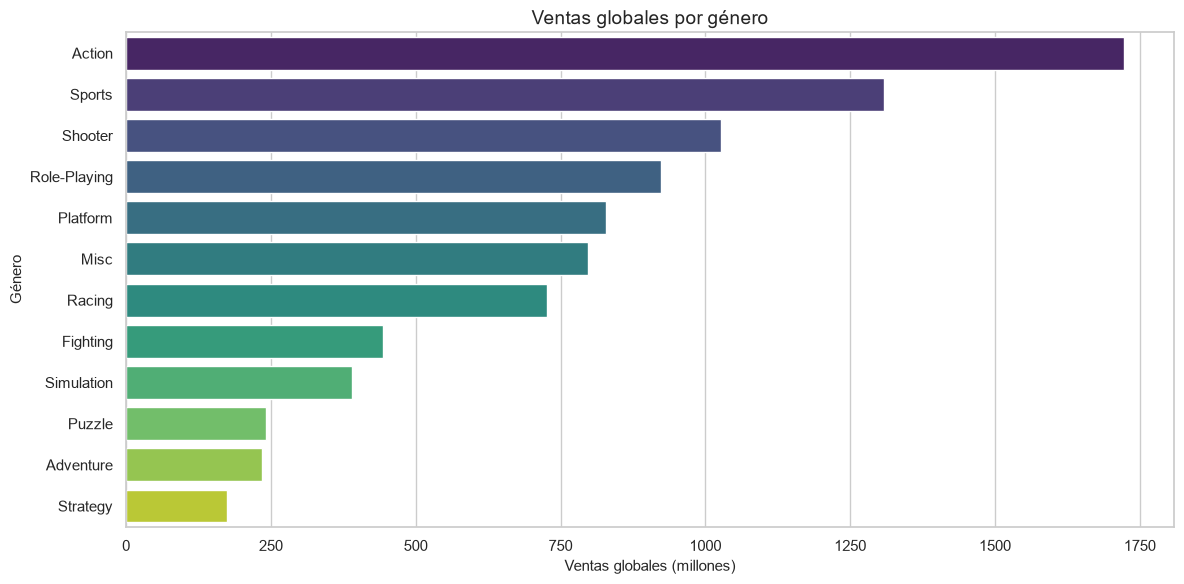

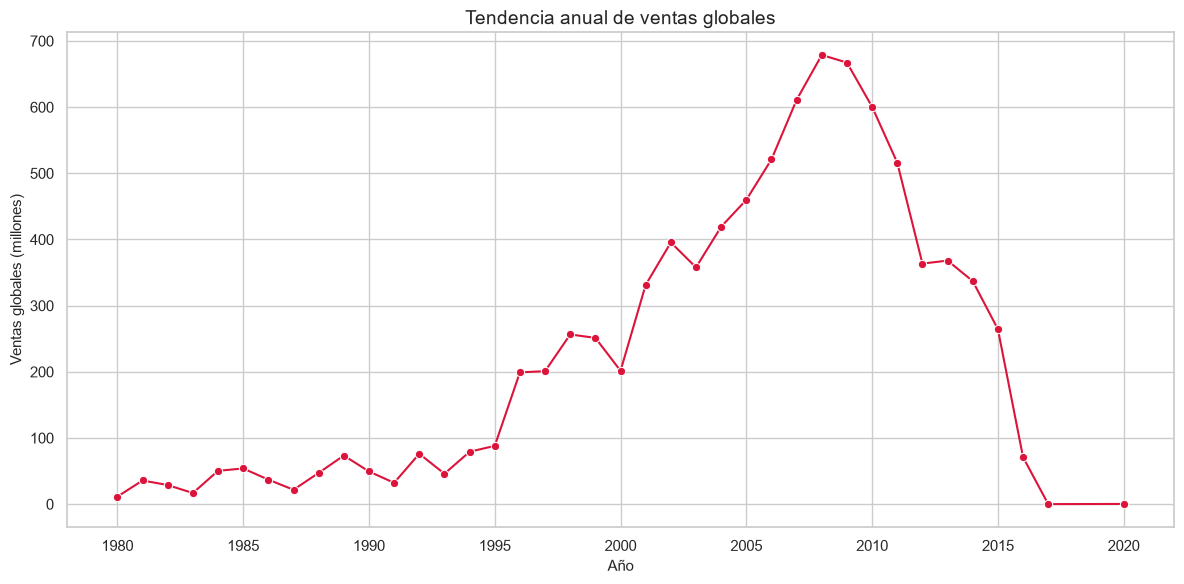

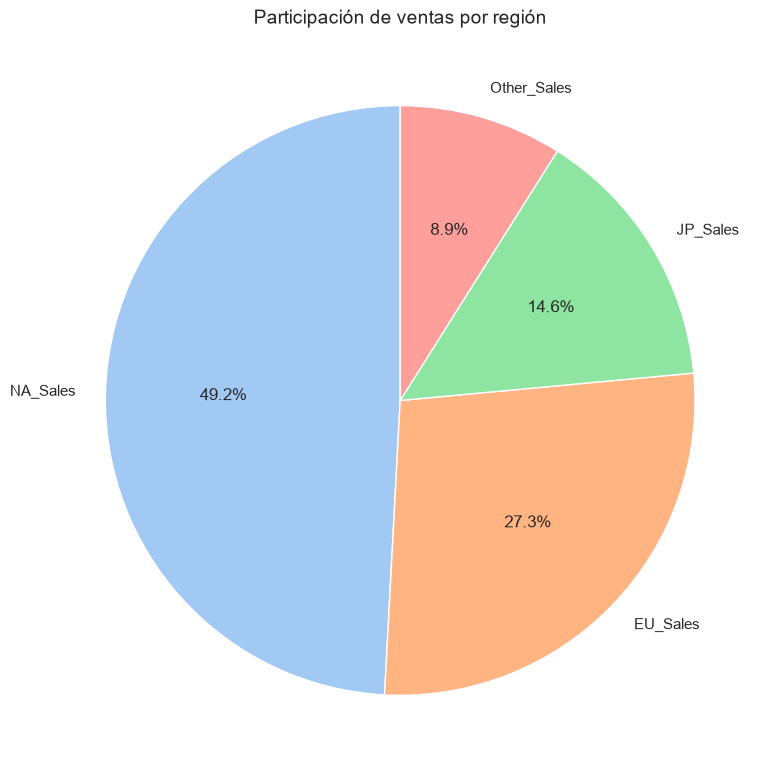

C:\Users\cosma\AppData\Local\Temp\ipykernel_10288\1831441364.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_publishers, x="Global_Sales", y="Publisher", palette="mako")


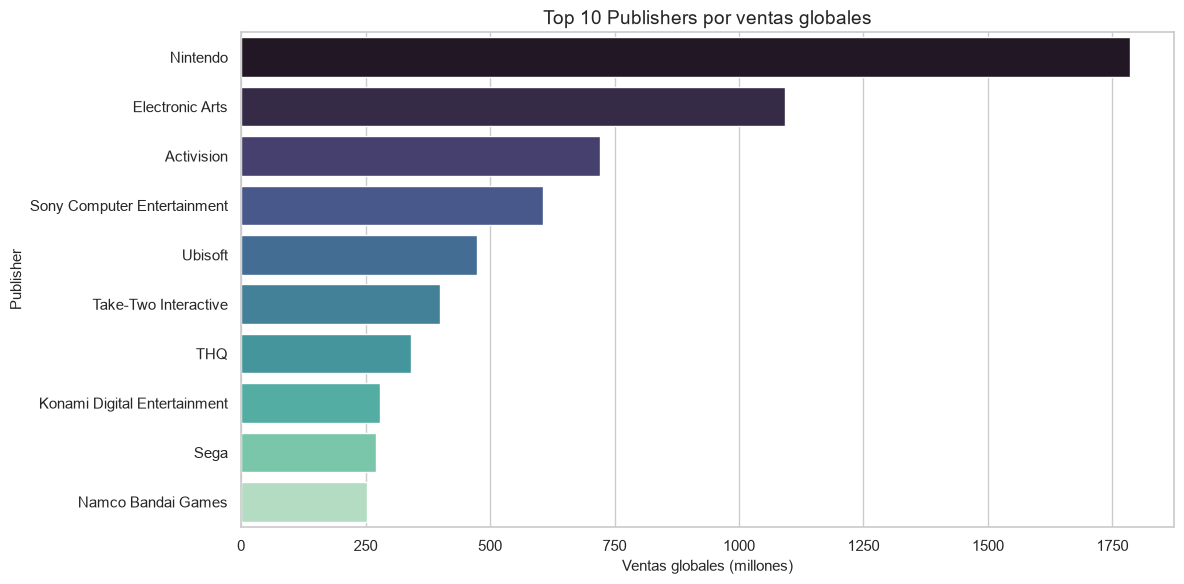

In [5]:

# ============================================================
# PARTE C: ANÁLISIS DESCRIPTIVO
# ============================================================

# --- C.1 Ventas globales por género ---
ventas_genero = (df.groupby("Genre")["Global_Sales"]
                   .sum()
                   .sort_values(ascending=False)
                   .reset_index())
print("\n=== Ventas por género ===")
print(ventas_genero)

# --- C.2 Tendencia anual de ventas globales ---
ventas_anuales = df.groupby("Year")["Global_Sales"].sum().reset_index()
print("\n=== Ventas anuales ===")
print(ventas_anuales)

# --- C.3 Ventas por región ---
regiones = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
ventas_region = df[regiones].sum().sort_values(ascending=False)
print("\n=== Ventas por región ===")
print(ventas_region)

# --- C.4 Top 10 publishers ---
top_publishers = (df.groupby("Publisher")["Global_Sales"]
                    .sum()
                    .sort_values(ascending=False)
                    .head(10)
                    .reset_index())
print("\n=== Top 10 Publishers ===")
print(top_publishers)


# --- C.5 VISUALIZACIONES (matplotlib + seaborn) ---

# 1) Gráfico de barras: ventas por género
plt.figure(figsize=(12, 6))
sns.barplot(data=ventas_genero, x="Global_Sales", y="Genre", palette="viridis")
plt.title("Ventas globales por género")
plt.xlabel("Ventas globales (millones)")
plt.ylabel("Género")
plt.tight_layout()
plt.savefig("01_ventas_genero.png", dpi=300)
plt.show()

# 2) Gráfico de línea: tendencia anual
plt.figure(figsize=(12, 6))
sns.lineplot(data=ventas_anuales, x="Year", y="Global_Sales",
             marker="o", color="crimson")
plt.title("Tendencia anual de ventas globales")
plt.xlabel("Año")
plt.ylabel("Ventas globales (millones)")
plt.tight_layout()
plt.savefig("02_tendencia_anual.png", dpi=300)
plt.show()

# 3) Gráfico circular: participación por región
plt.figure(figsize=(8, 8))
plt.pie(ventas_region, labels=ventas_region.index, autopct="%1.1f%%",
        colors=sns.color_palette("pastel"), startangle=90)
plt.title("Participación de ventas por región")
plt.tight_layout()
plt.savefig("03_participacion_region.png", dpi=300)
plt.show()

# 4) Barras horizontales: Top 10 publishers
plt.figure(figsize=(12, 6))
sns.barplot(data=top_publishers, x="Global_Sales", y="Publisher", palette="mako")
plt.title("Top 10 Publishers por ventas globales")
plt.xlabel("Ventas globales (millones)")
plt.ylabel("Publisher")
plt.tight_layout()
plt.savefig("04_top_publishers.png", dpi=300)
plt.show()

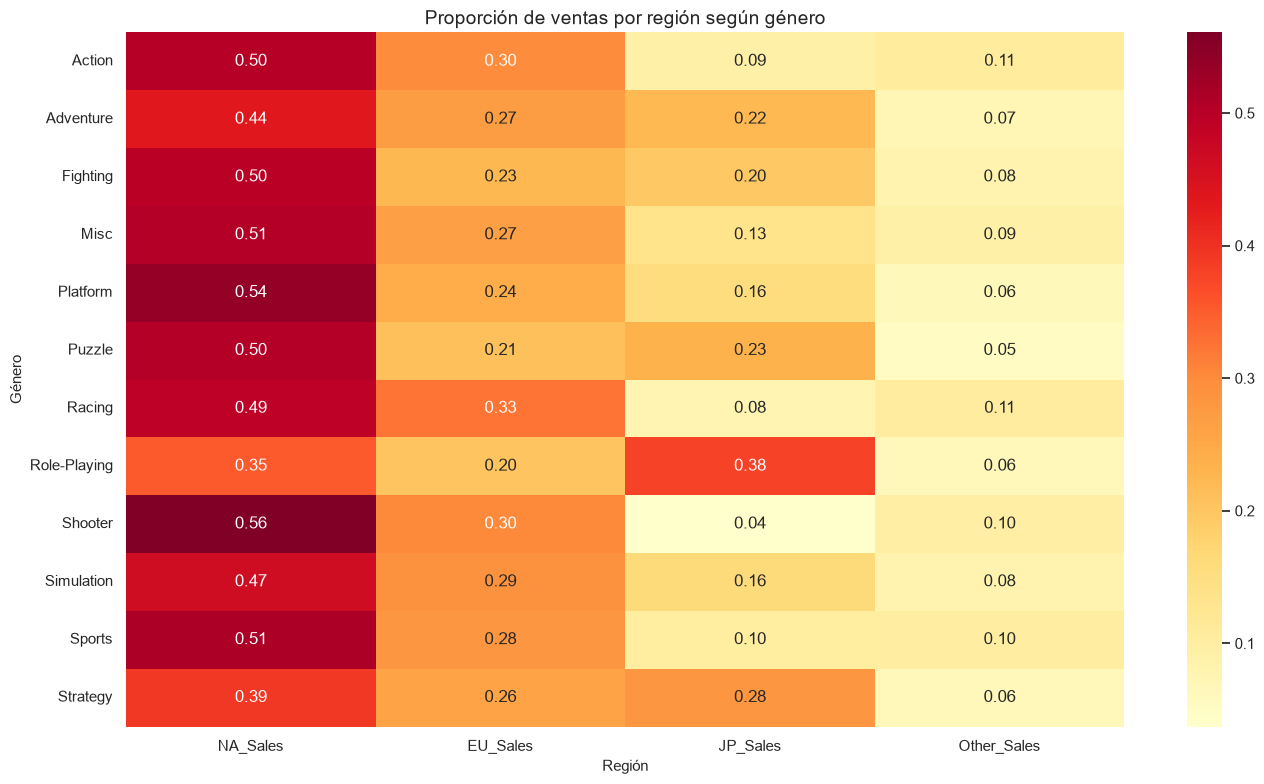

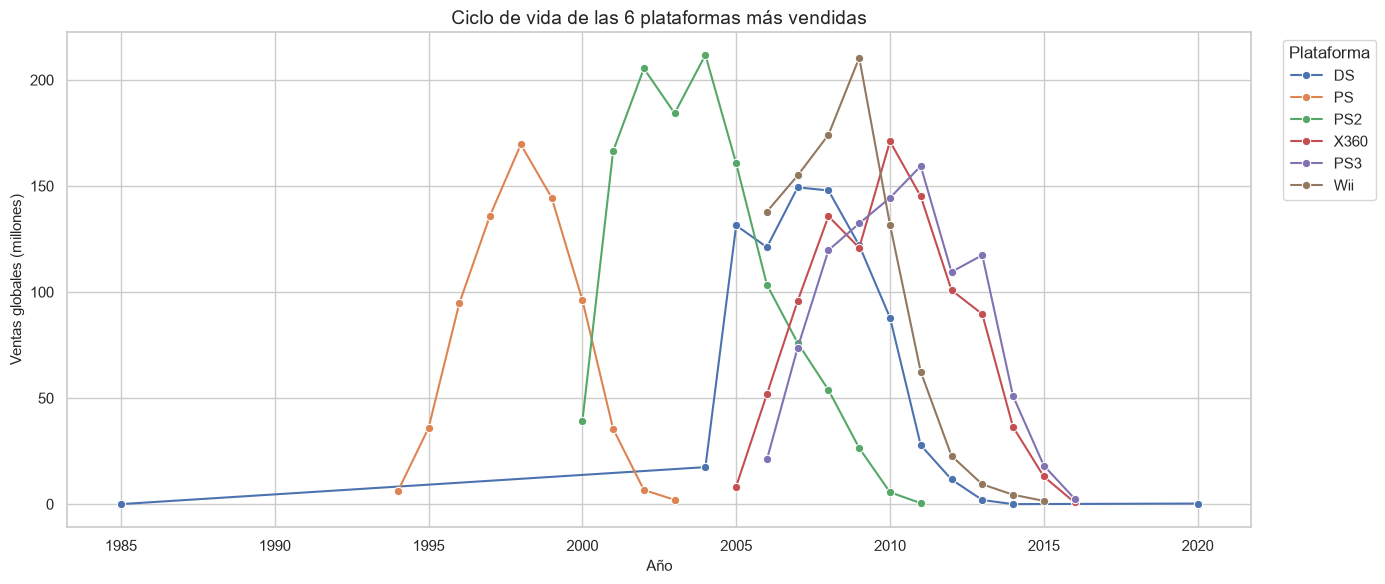


Top 5 publishers concentran: 53.06%
Top 10 publishers concentran: 70.55%
Top 20 publishers concentran: 85.64%


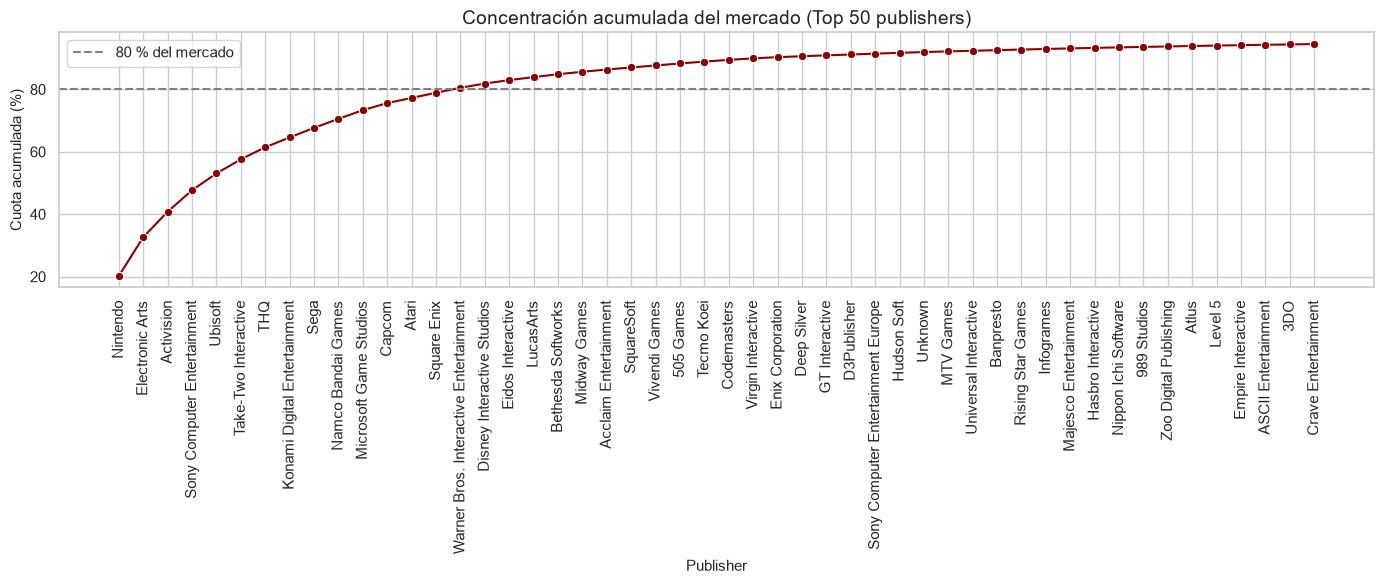


=== Años de los 50 juegos más vendidos ===
Year
1984    1
1985    1
1988    1
1989    2
1990    1
1996    2
1998    1
1999    1
2001    2
2002    2
2004    2
2005    5
2006    4
2007    3
2008    2
2009    5
2010    4
2011    3
2012    2
2013    3
2014    2
2015    1
Name: count, dtype: int64


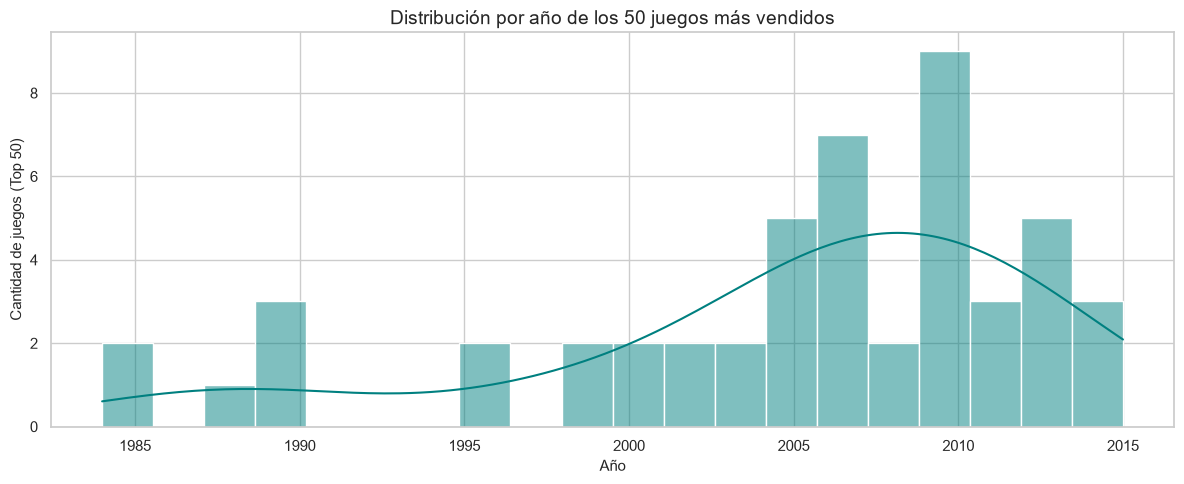

In [6]:

# ============================================================
# PARTE D: ANÁLISIS DIAGNÓSTICO
# ============================================================

# --- D.1 Distribución regional de ventas por género ---
genero_region = df.groupby("Genre")[regiones].sum()
genero_region_norm = genero_region.div(genero_region.sum(axis=1), axis=0)

plt.figure(figsize=(14, 8))
sns.heatmap(genero_region_norm, annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("Proporción de ventas por región según género")
plt.xlabel("Región")
plt.ylabel("Género")
plt.tight_layout()
plt.savefig("05_heatmap_genero_region.png", dpi=300)
plt.show()


# --- D.2 Ciclo de vida de las principales plataformas ---
top_plataformas = (df.groupby("Platform")["Global_Sales"]
                     .sum()
                     .sort_values(ascending=False)
                     .head(6).index.tolist())

df_plat = df[df["Platform"].isin(top_plataformas)]
evolucion_plat = (df_plat.groupby(["Year", "Platform"])["Global_Sales"]
                          .sum().reset_index())

plt.figure(figsize=(14, 6))
sns.lineplot(data=evolucion_plat, x="Year", y="Global_Sales",
             hue="Platform", marker="o")
plt.title("Ciclo de vida de las 6 plataformas más vendidas")
plt.xlabel("Año")
plt.ylabel("Ventas globales (millones)")
plt.legend(title="Plataforma", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("06_ciclo_plataformas.png", dpi=300)
plt.show()


# --- D.3 Concentración del mercado por publisher (Pareto) ---
cuota = (df.groupby("Publisher")["Global_Sales"]
           .sum()
           .sort_values(ascending=False)
           .reset_index())
cuota["Cuota_%"] = cuota["Global_Sales"] / cuota["Global_Sales"].sum() * 100
cuota["Cuota_Acum_%"] = cuota["Cuota_%"].cumsum()

top5  = cuota.head(5)["Cuota_%"].sum()
top10 = cuota.head(10)["Cuota_%"].sum()
top20 = cuota.head(20)["Cuota_%"].sum()
print(f"\nTop 5 publishers concentran: {top5:.2f}%")
print(f"Top 10 publishers concentran: {top10:.2f}%")
print(f"Top 20 publishers concentran: {top20:.2f}%")

# Curva de Pareto
plt.figure(figsize=(14, 6))
sns.lineplot(data=cuota.head(50), x="Publisher", y="Cuota_Acum_%",
             marker="o", color="darkred")
plt.axhline(y=80, color="gray", linestyle="--", label="80 % del mercado")
plt.title("Concentración acumulada del mercado (Top 50 publishers)")
plt.xlabel("Publisher")
plt.ylabel("Cuota acumulada (%)")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.savefig("07_pareto_publishers.png", dpi=300)
plt.show()


# --- D.4 Pregunta diagnóstica propia ---
# ¿Los juegos más vendidos se concentran en pocos años?
top50_juegos = df.nlargest(50, "Global_Sales")
print("\n=== Años de los 50 juegos más vendidos ===")
print(top50_juegos["Year"].value_counts().sort_index())

plt.figure(figsize=(12, 5))
sns.histplot(top50_juegos["Year"], bins=20, kde=True, color="teal")
plt.title("Distribución por año de los 50 juegos más vendidos")
plt.xlabel("Año")
plt.ylabel("Cantidad de juegos (Top 50)")
plt.tight_layout()
plt.savefig("08_top50_por_ano.png", dpi=300)
plt.show()

In [7]:
# ============================================================
# PARTE E: INTERPRETACIÓN ADMINISTRATIVA (resumen ejecutivo)
# ============================================================

print("\n========== RESUMEN EJECUTIVO ==========")
print(f"Total de juegos analizados: {len(df):,}")
print(f"Ventas globales totales: {df['Global_Sales'].sum():,.2f} millones")
print(f"Género más vendido: {ventas_genero.iloc[0]['Genre']} "
      f"({ventas_genero.iloc[0]['Global_Sales']:.2f} M)")
print(f"Año pico de ventas: {ventas_anuales.loc[ventas_anuales['Global_Sales'].idxmax(), 'Year']}")
print(f"Región líder: {ventas_region.index[0]} ({ventas_region.iloc[0]:.2f} M)")
print(f"Publisher dominante: {top_publishers.iloc[0]['Publisher']} "
      f"({top_publishers.iloc[0]['Global_Sales']:.2f} M)")


========== RESUMEN EJECUTIVO ==========
Total de juegos analizados: 16,327
Ventas globales totales: 8,820.36 millones
Género más vendido: Action (1722.88 M)
Año pico de ventas: 2008
Región líder: NA_Sales (4333.43 M)
Publisher dominante: Nintendo (1784.43 M)



=== REGRESIÓN LINEAL ===
R²: 1.0000
RMSE: 0.0052
Coeficientes: {'NA_Sales': np.float64(0.9999), 'EU_Sales': np.float64(0.9998), 'JP_Sales': np.float64(1.0001), 'Other_Sales': np.float64(0.9993)}
Intercepto: 0.0003


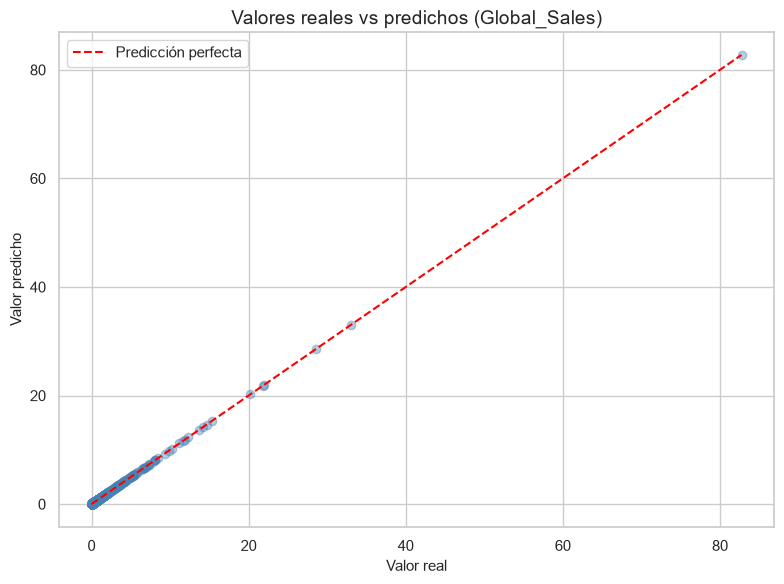

In [ ]:
# ============================================================
# EXTENSIÓN 1: REGRESIÓN LINEAL
# Predecir Global_Sales a partir de NA, EU, JP y Other
# ============================================================

X = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]]
y = df["Global_Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

modelo = LinearRegression()
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

print("\n=== REGRESIÓN LINEAL ===")
print(f"R²: {r2_score(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Coeficientes: {dict(zip(X.columns, modelo.coef_.round(4)))}")
print(f"Intercepto: {modelo.intercept_:.4f}")

# Gráfico: valores reales vs predichos
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.4, color="steelblue")
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linestyle="--", label="Predicción perfecta")
plt.title("Valores reales vs predichos (Global_Sales)")
plt.xlabel("Valor real")
plt.ylabel("Valor predicho")
plt.legend()
plt.tight_layout()
plt.savefig("09_regresion_real_vs_pred.png", dpi=300)
plt.show()


=== DISTRIBUCIÓN POR CLUSTER ===
Cluster
0    15639
1       46
2      641
3        1
Name: count, dtype: int64

=== PROMEDIO DE VENTAS POR CLUSTER ===
         NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales
Cluster                                                         
0            0.17      0.08      0.05         0.03          0.33
1            9.30      5.39      2.85         1.86         19.40
2            1.90      1.28      0.55         0.42          4.15
3           41.49     29.02      3.77         8.46         82.74


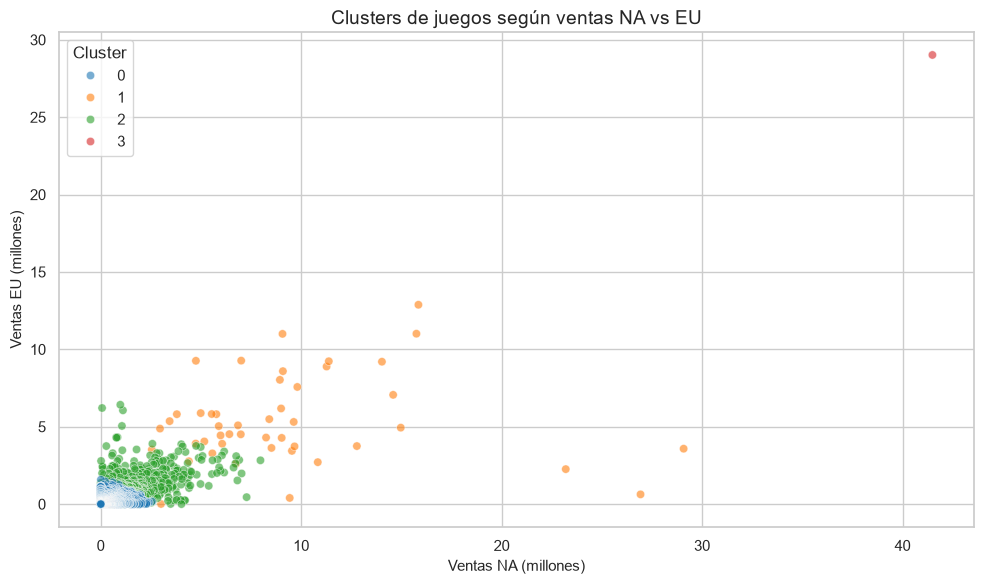

In [9]:
# ============================================================
# EXTENSIÓN 2: CLUSTERING (K-MEANS)
# Agrupar juegos por características de ventas
# ============================================================

features = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]]
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(features_scaled)

print("\n=== DISTRIBUCIÓN POR CLUSTER ===")
print(df["Cluster"].value_counts().sort_index())

print("\n=== PROMEDIO DE VENTAS POR CLUSTER ===")
print(df.groupby("Cluster")[["NA_Sales", "EU_Sales", "JP_Sales",
                              "Other_Sales", "Global_Sales"]].mean().round(2))

# Visualización del clustering
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="NA_Sales", y="EU_Sales", hue="Cluster",
                palette="tab10", alpha=0.6)
plt.title("Clusters de juegos según ventas NA vs EU", fontsize=14)
plt.xlabel("Ventas NA (millones)")
plt.ylabel("Ventas EU (millones)")
plt.tight_layout()
plt.savefig("08_clusters.png", dpi=300)
plt.show()